In [1]:
import sys
sys.path.append('../../')

import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
from scipy.sparse.linalg import spsolve
from scipy.sparse import diags, identity, bmat, kron, csc_matrix
from scipy.optimize import root
from abc import ABC, abstractmethod
from time import time

# Import methods
from QGP.Methods import *
from QGP.Soliton_Gen import *

plt.style.use('bmh')

plt.rcParams['figure.figsize'] = (7, 5)
plt.rcParams['legend.fontsize'] = 14
plt.rcParams["axes.titlesize"] = 24
plt.rcParams["axes.labelsize"] = 18
plt.rcParams["figure.titlesize"] = 24
plt.rcParams["ytick.labelsize"] = 14
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["axes.formatter.useoffset"]= False

i = 1j

## Error with theo black soliton

In [109]:
c = 0 #np.sqrt(2)/2
w_soliton, x_soliton = soliton(c, 0, soliton_type="dark", L=L, N=10_000, as_func=True)

def black_theo(x, t):
    return w_soliton(x - c * t)

Creating soliton...
Soliton created


In [113]:
dts = np.array([2**(-j) for j in range(11)])

# Time
tf = 3

# Space
h_1 = 0.05
h_2 = 0.01
L = 20

N_1 = int(2*L/h_1)
N_2 = int(2*L/h_2)

error_1 = np.zeros(len(dts))
error_2 = np.zeros(len(dts))

pars = {"k": 0}

ws_1 = []
ws_2 = []

# N_1
for dt in dts:
    w_ = CNFD(L, N_1, dt, tf, pars, "neumann")
    w_.set_w_theo(black_theo)
    ws_1 += [w_]

# N_2
for dt in dts:
    w_ = CNFD(L, N_2, dt, tf, pars, "neumann")
    w_.set_w_theo(black_theo)
    ws_2 += [w_]

In [114]:
# N_1
for j in range(len(dts)):
    w_ = ws_1[j]
    w_.solve()

In [115]:
# N_2
for j in range(len(dts)):
    w_ = ws_2[j]
    w_.solve()

In [116]:
for j in range(len(dts)):
    e_1 = ws_1[j].get_error(tf)
    e_2 = ws_2[j].get_error(tf)
    
    error_1[j] = e_1
    error_2[j] = e_2

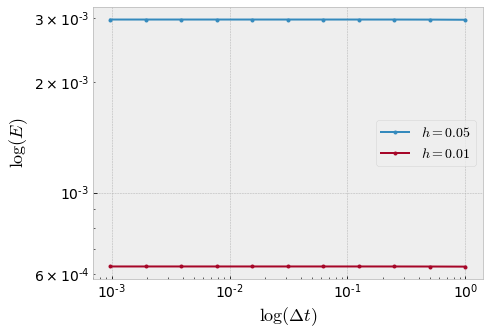

In [117]:
dts_to_plot = dts[:-5]
plt.plot(dts, error_1, ".-", label=r"$h=0.05$")
plt.plot(dts, error_2, ".-", label=r"$h=0.01$")
#plt.plot(dts_to_plot, dts_to_plot**2*np.exp(-2), label="slope-{} line".format(2))
plt.yscale("log")
plt.xscale("log")

plt.xlabel(r"$\log(\Delta t)$")
plt.ylabel(r"$\log(E)$")

plt.legend()

plt.savefig("Img/errors_black.png", dpi=300, bbox_inches = "tight")
plt.show()